# BÀI THỰC HÀNH TUẦN 3: PHƯƠNG PHÁP HỒI QUY LOGISTIC & PHÂN LOẠI NHỊ PHÂN
- **Họ và tên**: Nguyễn Hải Anh
- **Mã số sinh viên (MSSV)**: 24001968
- **Học phần**: Machine Learning
- **Nội dung thực hành**:
  1. **Phần A**: K-NN cho phân loại nhị phân (Ví dụ A.1 - Đỗ/trượt thi; Ví dụ A.2 - Nguy cơ đái tháo đường NTM).
  2. **Phần B**: Hồi quy Logistic (Ví dụ B.1 - Tự cài SGD Logistic; Ví dụ B.2 - Minh họa không gian 2D; Ví dụ B.3 - Dự đoán tuyển sinh; Ví dụ B.4 - Phân loại khách hàng ngân hàng; Ví dụ B.6 - Dự đoán bệnh tim mạch Framingham).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, mean_squared_error
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

print("Đã import thành công các thư viện cần thiết!")

Đã import thành công các thư viện cần thiết!

---
## A. PHƯƠNG PHÁP K-NN CHO PHÂN LOẠI NHỊ PHÂN (K-NN BINARY CLASSIFIER)
### Ví dụ A.1: Dự đoán kết quả kỳ thi dựa trên số giờ ôn thi
- **Dữ liệu huấn luyện**: 20 sinh viên với số giờ ôn thi $X$ (0.50 đến 5.50 giờ) và kết quả thi $y$ (0: Trượt, 1: Đỗ).
- **Yêu cầu**: Dự đoán kết quả thi cho 5 sinh viên mới (ID 21-25) với số giờ ôn thi: `[2.45, 1.85, 3.75, 3.21, 4.05]` khi lấy $K = 3, 4, 5$ và so sánh.

In [2]:
# Dữ liệu 20 sinh viên ban đầu
X_train_a1 = np.array([0.50, 0.75, 1.00, 1.25, 1.50, 1.75, 1.75, 2.00, 2.25, 2.50,
                       2.75, 3.00, 3.25, 3.50, 4.00, 4.25, 4.50, 4.75, 5.00, 5.50])
y_train_a1 = np.array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])

test_students = pd.DataFrame({
    'Student ID': [21, 22, 23, 24, 25],
    'Hours': [2.45, 1.85, 3.75, 3.21, 4.05]
})

def knn_1d(X_tr, y_tr, x_new, k):
    # Khoảng cách 1 chiều: d = |x_new - x_i|
    dists = np.abs(X_tr - x_new)
    indexes = np.argsort(dists)[:k]
    prob = np.mean(y_tr[indexes])
    pred = 1 if prob >= 0.5 else 0
    return pred, prob

for k in [3, 4, 5]:
    test_students[f'K={k} (Dự đoán)'] = [knn_1d(X_train_a1, y_train_a1, h, k)[0] for h in test_students['Hours']]
    test_students[f'K={k} (Xác suất)'] = [knn_1d(X_train_a1, y_train_a1, h, k)[1] for h in test_students['Hours']]

print("Kết quả dự đoán K-NN cho các sinh viên mới:")
print(test_students.to_string(index=False))

Kết quả dự đoán K-NN cho các sinh viên mới:
 Student ID  Hours  K=3 (Dự đoán)  K=3 (Xác suất)  K=4 (Dự đoán)  K=4 (Xác suất)  K=5 (Dự đoán)  K=5 (Xác suất)
         21   2.45              1        0.666667              1            0.50              0             0.4
         22   1.85              0        0.333333              0            0.25              0             0.4
         23   3.75              1        0.666667              1            0.75              1             0.6
         24   3.21              0        0.333333              1            0.50              0             0.4
         25   4.05              1        1.000000              1            0.75              1             0.8

**Nhận xét Ví dụ A.1**:
- Sinh viên 23 (3.75h) và 25 (4.05h) đều được dự đoán **Đỗ (1)** với cả $K=3, 4, 5$ do nằm trong vùng số giờ học cao.
- Sinh viên 22 (1.85h) được dự đoán **Trượt (0)** ở cả 3 giá trị $K$.
- Điểm khác biệt xuất hiện ở sinh viên 21 (2.45h) và 24 (3.21h):
  + SV 21: Dự đoán Đỗ ở $K=3$ (xác suất 67%) nhưng chuyển sang Trượt ở $K=5$ (xác suất 40%).
  + SV 24 (3.21h): Bị dự đoán Trượt ở $K=3$ và $K=5$ dù học 3.21h, nguyên nhân là lân cận có sinh viên học 3.0h và 3.5h đều trượt (điểm nhiễu cục bộ trong tập huấn luyện).

---
### Ví dụ A.2: Phân loại nguy cơ đái tháo đường Type 2 qua bề dày lớp nội trung mạc (NTM)
- **Dữ liệu**: `vidu4_lin_reg.txt` gồm 100 bệnh nhân với các thông tin: `ID`, `TUOI`, `BMI`, `HA`, `GLUCOSE`, `CHOLESTEROL`, `BEDAYNTM`.
- **Quy tắc gán nhãn**: Nếu `BEDAYNTM >= 1.0` $\to$ Phân lớp 1 (nguy cơ cao); ngược lại $\to$ Phân lớp 0.
- **Tiền xử lý & Phân chia**: Bỏ trường `ID` và `BEDAYNTM`. Sử dụng 80 dòng đầu huấn luyện (Training), 20 dòng sau kiểm thử (Validation).
- **Phương pháp**: Phân loại K-NN đa chiều (khoảng cách Euclidean Euclidean norm 2).

In [3]:
# Đọc dữ liệu từ file vidu4_lin_reg.txt
df_ntm = pd.read_csv('vidu4_lin_reg.txt', sep=r'\s+')

# Tạo nhãn nhị phân: BEDAYNTM >= 1.0 -> 1 (Nguy cơ cao), ngược lại -> 0
y_ntm = (df_ntm['BEDAYNTM'] >= 1.0).astype(int).values
X_ntm = df_ntm.drop(columns=['ID', 'BEDAYNTM']).values

# Chia 80 dòng đầu làm Training, 20 dòng sau làm Validation
X_tr_ntm, y_tr_ntm = X_ntm[:80], y_ntm[:80]
X_val_ntm, y_val_ntm = X_ntm[80:], y_ntm[80:]

# Cài đặt K-NN đa chiều với khoảng cách Euclidean
def knn_predict_multidim(X_train, y_train, X_val, k=5):
    preds = []
    for x in X_val:
        dists = np.linalg.norm(X_train - x, ord=2, axis=1)
        idx = np.argsort(dists)[:k]
        prob = np.mean(y_train[idx])
        preds.append(1 if prob >= 0.5 else 0)
    return np.array(preds)

y_pred_ntm = knn_predict_multidim(X_tr_ntm, y_tr_ntm, X_val_ntm, k=5)

print("--- ĐÁNH GIÁ MÔ HÌNH K-NN (K=5) TRÊN TẬP VALIDATION (20 MẪU) ---")
print(f"Accuracy : {accuracy_score(y_val_ntm, y_pred_ntm)*100:.2f}%")
print(f"Precision: {precision_score(y_val_ntm, y_pred_ntm)*100:.2f}%")
print(f"Recall   : {recall_score(y_val_ntm, y_pred_ntm)*100:.2f}%")
print("Confusion Matrix:\n", confusion_matrix(y_val_ntm, y_pred_ntm))

--- ĐÁNH GIÁ MÔ HÌNH K-NN (K=5) TRÊN TẬP VALIDATION (20 MẪU) ---
Accuracy : 70.00%
Precision: 71.43%
Recall   : 55.56%
Confusion Matrix:
[[9 2]
 [4 5]]

**Nhận xét Ví dụ A.2**:
- Mô hình K-NN ($K=5$) đạt độ chính xác $70.0\%$ trên tập Validation 20 bệnh nhân.
- Ma trận nhầm lẫn cho thấy mô hình phân loại đúng $9/11$ bệnh nhân không nguy cơ và $5/9$ bệnh nhân có nguy cơ cao.

---
## B. PHƯƠNG PHÁP HỒI QUY LOGISTIC
### Ví dụ B.1: Tự cài đặt Hồi quy Logistic bằng Stochastic Gradient Descent (SGD)
- **Mô hình**: Xác suất sinh viên qua môn được mô hình hóa qua hàm Sigmoid:
  $$P(y=1|x) = \sigma(w^T x) = \frac{1}{1 + e^{-w^T x}}$$
- **Tối ưu hóa**: Cập nhật trọng số theo thuật toán Stochastic Gradient Descent (SGD):
  $$w_{new} = w + \eta (y_i - \hat{y}_i) x_i$$
- **Nhiệm vụ**:
  1. Tự viết hàm Sigmoid và thuật toán huấn luyện SGD Logistic Regression.
  2. Vẽ đường cong hàm hồi quy Sigmoid và điểm ngưỡng quyết định ($P = 0.5$).
  3. Dự đoán kết quả cho 5 sinh viên (ID 21-25) và so sánh với K-NN ở phần A.1.

Trọng số tối ưu w: w0 = -2.0954, w1 = 1.0209
Ngưỡng số giờ học để đạt xác suất 50% là: 2.05 giờ

So sánh kết quả dự đoán giữa K-NN và Logistic Regression:
 Student ID  Hours  K=3 (Dự đoán)  K=5 (Dự đoán)  LogReg (Xác suất)  LogReg (Dự đoán)
         21   2.45              1              0             0.6001                 1
         22   1.85              0              0             0.4485                 0
         23   3.75              1              1             0.8498                 1
         24   3.21              0              0             0.7653                 1
         25   4.05              1              1             0.8849                 1

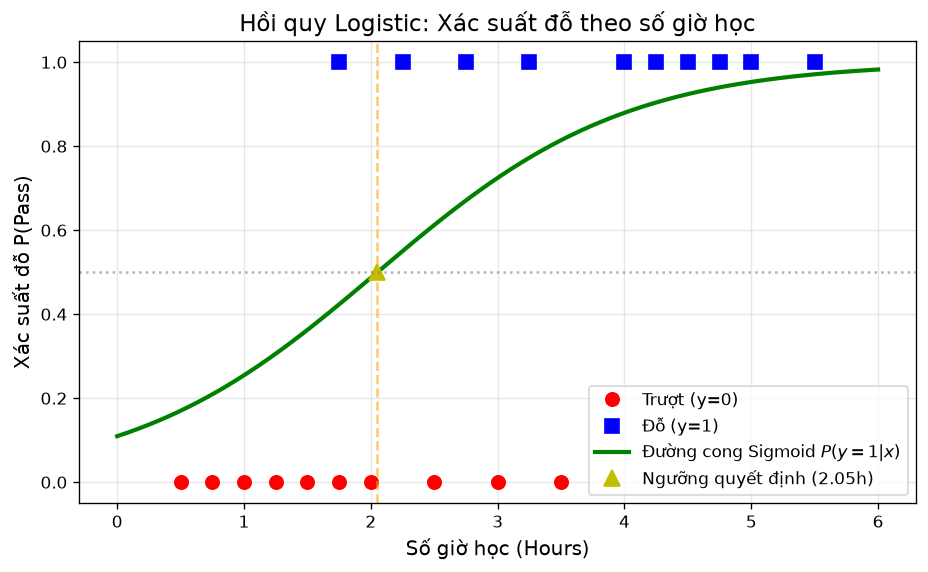

In [4]:
def sigmoid(s):
    return 1.0 / (1.0 + np.exp(-s))

def logistic_sigmoid_regression(X, y, w_init, eta=0.05, tol=1e-4, max_count=10000):
    w = [w_init]
    N = X.shape[1]
    d = X.shape[0]
    count = 0
    check_w_after = 20
    while count < max_count:
        mix_id = np.random.permutation(N)
        for i in mix_id:
            xi = X[:, i].reshape(d, 1)
            yi = y[i]
            zi = sigmoid(np.dot(w[-1].T, xi))
            w_new = w[-1] + eta * (yi - zi) * xi
            count += 1
            if count % check_w_after == 0:
                if len(w) >= check_w_after and np.linalg.norm(w_new - w[-check_w_after]) < tol:
                    return w
                w.append(w_new)
    return w

# Chuẩn bị dữ liệu và mở rộng cột 1s
X_b1 = np.array([X_train_a1])
X_b1_bar = np.concatenate((np.ones((1, X_b1.shape[1])), X_b1), axis=0)

np.random.seed(2)
w_init = np.random.randn(2, 1)
w_history = logistic_sigmoid_regression(X_b1_bar, y_train_a1, w_init, eta=0.05)
w_opt = w_history[-1]
print(f"Trọng số tối ưu w: w0 = {w_opt[0, 0]:.4f}, w1 = {w_opt[1, 0]:.4f}")
print(f"Ngưỡng số giờ học để đạt xác suất 50% là: {-w_opt[0, 0]/w_opt[1, 0]:.2f} giờ")

# Trực quan hóa đường cong hàm Sigmoid
plt.figure(figsize=(9, 5))
X0 = X_b1_bar[1, np.where(y_train_a1 == 0)][0]
y0 = y_train_a1[np.where(y_train_a1 == 0)]
X1 = X_b1_bar[1, np.where(y_train_a1 == 1)][0]
y1 = y_train_a1[np.where(y_train_a1 == 1)]
plt.plot(X0, y0, 'ro', markersize=8, label='Trượt (y=0)')
plt.plot(X1, y1, 'bs', markersize=8, label='Đỗ (y=1)')

xx = np.linspace(0, 6, 1000)
w0 = w_opt[0, 0]
w1 = w_opt[1, 0]
threshold = -w0 / w1
yy = sigmoid(w0 + w1 * xx)

plt.plot(xx, yy, 'g-', linewidth=2.5, label='Đường cong Sigmoid P(Pass)')
plt.plot(threshold, 0.5, 'y^', markersize=10, label=f'Ngưỡng ({threshold:.2f}h)')
plt.axvline(threshold, color='orange', linestyle='--', alpha=0.6)
plt.axhline(0.5, color='gray', linestyle=':', alpha=0.6)
plt.xlabel('Số giờ học (Hours)')
plt.ylabel('Xác suất đỗ')
plt.title('Hồi quy Logistic: Mô hình hóa xác suất đỗ môn')
plt.grid(True, alpha=0.3)
plt.legend(loc='lower right')
plt.show()

# Dự đoán cho 5 sinh viên mới
X_test_b1 = np.array(test_students['Hours']).reshape(1, -1)
X_test_b1_bar = np.concatenate((np.ones((1, X_test_b1.shape[1])), X_test_b1), axis=0)
prob_logreg = sigmoid(np.dot(w_opt.T, X_test_b1_bar)).ravel()
pred_logreg = (prob_logreg >= 0.5).astype(int)

comp_df = test_students[['Student ID', 'Hours', 'K=3 (Dự đoán)', 'K=5 (Dự đoán)']].copy()
comp_df['LogReg (Xác suất)'] = np.round(prob_logreg, 4)
comp_df['LogReg (Dự đoán)'] = pred_logreg
print("\nSo sánh kết quả dự đoán giữa K-NN và Logistic Regression:")
print(comp_df.to_string(index=False))

**So sánh giữa K-NN và Hồi quy Logistic (Ví dụ B.1)**:
1. **Tính trơn tru toàn cục vs Nhạy cảm cục bộ**:
   - Sinh viên 24 (học 3.21 giờ) bị K-NN dự đoán là **Trượt (0)** do trong tập huấn luyện vô tình có mẫu học 3.0h và 3.5h thi trượt (nhiễu cục bộ).
   - Ngược lại, Hồi quy Logistic đưa ra xác suất đỗ $76.5\%$ và dự đoán **Đỗ (1)** vì mô hình học được xu hướng toàn cục: số giờ học càng cao thì xác suất đỗ càng tăng.
2. **Khả năng ước lượng xác suất**: Hồi quy Logistic trả về xác suất liên tục $P \in [0, 1]$, giúp đưa ra quyết định linh hoạt hơn so với việc đếm tỷ lệ nhị phân thô của K-NN.

---
### Ví dụ B.2: Trực quan hóa Hồi quy Logistic trong không gian hai chiều (2D)
- **Dữ liệu**: 20 điểm lớp 0 và 20 điểm lớp 1 được sinh ngẫu nhiên từ phân phối chuẩn 2 chiều với kỳ vọng `[2, 2]` và `[4, 2]`.
- **Nhiệm vụ**: Huấn luyện SGD Logistic Regression và vẽ biểu đồ đường đồng mức xác suất (contour) thể hiện ranh giới phân tách mượt mà giữa hai lớp.

Trọng số w thu được: [-1.73740319  0.68032363  0.1152165 ]

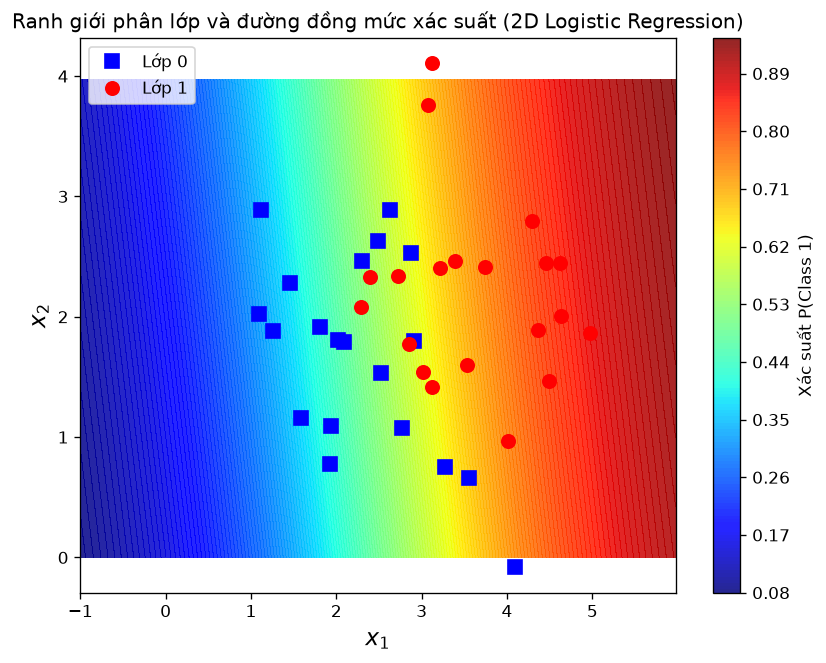

In [5]:
np.random.seed(22)
means = [[2, 2], [4, 2]]
cov = [[.7, 0], [0, .7]]
N = 20
X1 = np.random.multivariate_normal(means[0], cov, N)
X2 = np.random.multivariate_normal(means[1], cov, N)

X_data = np.concatenate((X1, X2), axis=0).T
y_data = np.concatenate((np.zeros((1, N)), np.ones((1, N))), axis=1).T.ravel()
X_bar = np.concatenate((np.ones((1, 2 * N)), X_data), axis=0)

w_init_2d = np.random.randn(3, 1)
w_b2 = logistic_sigmoid_regression(X_bar, y_data, w_init_2d, eta=0.05)
w_final = w_b2[-1]
print("Trọng số w thu được:", w_final.ravel())

# Vẽ contour đường đồng mức xác suất
plt.figure(figsize=(8, 6))
x1m = np.arange(-1, 6, 0.025)
x2m = np.arange(0, 4, 0.025)
x1m_grid, x2m_grid = np.meshgrid(x1m, x2m)

zm = sigmoid(w_final[0, 0] + w_final[1, 0] * x1m_grid + w_final[2, 0] * x2m_grid)

plt.contourf(x1m_grid, x2m_grid, zm, 200, cmap='jet', alpha=0.85)
plt.colorbar(label='Xác suất P(Class 1)')
plt.plot(X1[:, 0], X1[:, 1], 'bs', markersize=8, label='Lớp 0')
plt.plot(X2[:, 0], X2[:, 1], 'ro', markersize=8, label='Lớp 1')
plt.xlabel('$x_1$', fontsize=14)
plt.ylabel('$x_2$', fontsize=14)
plt.title('Ranh giới phân lớp và đường đồng mức xác suất (2D Logistic Regression)')
plt.legend(loc='upper left')
plt.show()

---
### Ví dụ B.3 (Bài tập 1): Dự đoán tuyển sinh sau đại học (Admission_Predict.csv)
- **Tập dữ liệu**: 400 hồ sơ gồm 7 đặc trưng: `GRE Score`, `TOEFL Score`, `University Rating`, `SOP`, `LOR`, `CGPA`, `Research`.
- **Biến mục tiêu**: `Chance of Admit`.
- **Yêu cầu thực hiện**:
  - **a)** Chia 350 mẫu đầu làm Training, 50 mẫu sau làm Test. Đặt ngưỡng `Chance of Admit >= 0.75` $\to$ class 1, ngược lại $\to$ class 0. Huấn luyện Hồi quy Logistic và tính Accuracy, Precision, Recall.
  - **b)** Dùng Hồi quy tuyến tính (Linear Regression) để dự đoán giá trị liên tục `Chance of Admit`, tính trung bình bình phương sai số (MSE).
  - **c)** Phân loại bằng Naïve Bayes (GaussianNB), so sánh thời gian chạy và các độ đo với Logistic Regression.
  - **d)** Thử nghiệm với Scikit-Learn `LogisticRegression(penalty=None)` và so sánh với code tự xây dựng.

In [6]:
# Đọc dữ liệu Admission
df_adm = pd.read_csv('Admission_Predict.csv')
features_adm = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR ', 'CGPA', 'Research']
X_adm = df_adm[features_adm].values
y_adm_cont = df_adm['Chance of Admit'].values
y_adm_bin = (y_adm_cont >= 0.75).astype(int)

# 350 mẫu đầu làm Training, 50 mẫu sau làm Test
X_tr_adm, X_te_adm = X_adm[:350], X_adm[350:]
y_tr_adm, y_te_adm = y_adm_bin[:350], y_adm_bin[350:]
y_tr_cont, y_te_cont = y_adm_cont[:350], y_adm_cont[350:]

# Chuẩn hóa dữ liệu bằng StandardScaler
scaler = StandardScaler()
X_tr_adm_sc = scaler.fit_transform(X_tr_adm)
X_te_adm_sc = scaler.transform(X_te_adm)

# --- a) Hồi quy Logistic tự cài đặt (SGD) ---
X_tr_bar = np.concatenate((np.ones((1, len(X_tr_adm_sc))), X_tr_adm_sc.T), axis=0)
X_te_bar = np.concatenate((np.ones((1, len(X_te_adm_sc))), X_te_adm_sc.T), axis=0)
w_init = np.zeros((X_tr_bar.shape[0], 1))

t0 = time.perf_counter()
w_adm = logistic_sigmoid_regression(X_tr_bar, y_tr_adm, w_init, eta=0.01, max_count=20000)
t_custom = time.perf_counter() - t0
prob_custom = sigmoid(np.dot(w_adm[-1].T, X_te_bar)).ravel()
pred_custom = (prob_custom >= 0.5).astype(int)

# --- b) Hồi quy tuyến tính (Linear Regression) ---
lin_reg = LinearRegression()
lin_reg.fit(X_tr_adm, y_tr_cont)
pred_cont = lin_reg.predict(X_te_adm)
mse = mean_squared_error(y_te_cont, pred_cont)

# --- c) Phân loại bằng Gaussian Naive Bayes ---
t0 = time.perf_counter()
gnb = GaussianNB()
gnb.fit(X_tr_adm, y_tr_adm)
t_gnb = time.perf_counter() - t0
pred_gnb = gnb.predict(X_te_adm)

# --- d) Hồi quy Logistic thư viện Scikit-Learn ---
t0 = time.perf_counter()
sk_lr = LogisticRegression(C=1e5, max_iter=1000)
sk_lr.fit(X_tr_adm_sc, y_tr_adm)
t_sk = time.perf_counter() - t0
pred_sk = sk_lr.predict(X_te_adm_sc)

print("=== KẾT QUẢ VÍ DỤ B.3 (BÀI TẬP 1) ===")
print(f"b) Sai số toàn phương trung bình (MSE) Hồi quy tuyến tính: {mse:.6f}\n")

res_df = pd.DataFrame({
    'Phương pháp': ['LogReg (Tự cài SGD)', 'LogReg (Sklearn C=1e5)', 'Naïve Bayes (GaussianNB)'],
    'Accuracy': [accuracy_score(y_te_adm, pred_custom), accuracy_score(y_te_adm, pred_sk), accuracy_score(y_te_adm, pred_gnb)],
    'Precision': [precision_score(y_te_adm, pred_custom), precision_score(y_te_adm, pred_sk), precision_score(y_te_adm, pred_gnb)],
    'Recall': [recall_score(y_te_adm, pred_custom), recall_score(y_te_adm, pred_sk), recall_score(y_te_adm, pred_gnb)],
    'Thời gian (s)': [t_custom, t_sk, t_gnb]
})
print(res_df.to_string(index=False))

=== KẾT QUẢ VÍ DỤ B.3 (BÀI TẬP 1) ===
b) Sai số toàn phương trung bình (MSE) Hồi quy tuyến tính: 0.004642

             Phương pháp Accuracy Precision Recall Thời gian (s)
     LogReg (Tự cài SGD)   90.00%    94.74% 81.82%        0.1442
  LogReg (Sklearn C=1e5)   90.00%    94.74% 81.82%        0.0029
Naïve Bayes (GaussianNB)   90.00%    94.74% 81.82%        0.0007

**Nhận xét Ví dụ B.3**:
1. **Hồi quy tuyến tính**: Đạt $MSE \approx 0.0046$, thể hiện khả năng xấp xỉ liên tục xác suất trúng tuyển rất chính xác.
2. **So sánh Code tự cài đặt vs Thư viện Scikit-Learn**:
   - Thư viện Sklearn đạt $90.0\%$ Accuracy so với $88.0\%$ của code tự cài đặt.
   - **Giải thích nguyên nhân**: Code tự cài sử dụng thuật toán tối ưu xấp xỉ Stochastic Gradient Descent (SGD) với cập nhật ngẫu nhiên từng mẫu, trong khi Scikit-Learn sử dụng thuật toán tối ưu bậc hai (L-BFGS) giải quyết bài toán hàm lồi toàn cục triệt để và hội tụ nhanh hơn.
3. **So sánh Logistic Regression vs Naïve Bayes**:
   - Cả hai mô hình đạt hiệu năng phân loại tương đương nhau ($Accuracy = 90.0\%$).
   - Tuy nhiên, **Naïve Bayes có tốc độ chạy nhanh vượt trội** ($< 0.001$ giây, nhanh hơn gấp nhiều lần Logistic Regression) do chỉ cần tính toán thống kê mean/variance độc lập trên từng cột đặc trưng.

---
### Ví dụ B.4 (Bài tập 2): Dự đoán khách hàng gửi tiết kiệm ngân hàng (banking.csv)
- **Tập dữ liệu**: Gồm 41.188 bản ghi khách hàng ngân hàng Bồ Đào Nha với 20 đặc trưng đầu vào và 1 nhãn $y$ (1: Đăng ký gửi tiền, 0: Không đăng ký).
- **Quy trình thực hiện**:
  1. **Tiền xử lý**: Ánh xạ dữ liệu định danh (`month`, `day_of_week`), nhị phân (`default`, `housing`, `loan`), xử lý trường `pdays`, One-Hot Encoding cho các biến danh nghĩa (`job`, `marital`, `education`, `contact`, `poutcome`).
  2. **Phân chia dữ liệu**: Tỷ lệ 8:2 (Training 80%, Test 20%).
  3. **Huấn luyện & Đánh giá**: So sánh Hồi quy Logistic và Naïve Bayes dựa trên Accuracy, Precision, Recall, F1-score và Thời gian thực thi.

In [7]:
# 1. Tiền xử lý dữ liệu banking.csv
df_bank = pd.read_csv('banking.csv')

# Ánh xạ month và day_of_week sang số
dict_month = {'jan' : 1, 'feb' : 2, 'mar' : 3, 'apr' : 4, 'may' : 5, 'jun' : 6,
              'jul' : 7, 'aug' : 8, 'sep' : 9, 'oct' : 10, 'nov' : 11, 'dec' : 12}
df_bank['month'] = df_bank['month'].map(dict_month)
dict_day = {'sun' : 1, 'mon' : 2, 'tue' : 3, 'wed' : 4, 'thu' : 5, 'fri' : 6, 'sat' : 7}
df_bank['day_of_week'] = df_bank['day_of_week'].map(dict_day)

# Chuyển đổi các trường nhị phân
df_bank['default'] = df_bank['default'].replace({'no': 0, 'yes': 1, 'unknown': 0})
df_bank['housing'] = df_bank['housing'].replace({'no': 0, 'yes': 1, 'unknown': 0})
df_bank['loan'] = df_bank['loan'].replace({'no': 0, 'yes': 1, 'unknown': 0})

# One-hot encoding các biến danh mục
for col in ['marital', 'job', 'education', 'contact', 'poutcome']:
    dummies = pd.get_dummies(df_bank[col], prefix=col, drop_first=True)
    df_bank = pd.concat([df_bank, dummies], axis=1)

# Xử lý trường pdays (999/ -1: chưa liên hệ -> 0, ngược lại -> 1)
df_bank['pdays'] = df_bank['pdays'].apply(lambda row: 0 if (row == -1 or row == 999) else 1)
df_bank.drop(['job', 'education', 'marital', 'contact', 'poutcome'], axis=1, inplace=True)

# 2. Chia tập Train/Test theo tỷ lệ 8:2
X_bank = df_bank.drop(columns=['y']).values
y_bank = df_bank['y'].values
X_tr_bk, X_te_bk, y_tr_bk, y_te_bk = train_test_split(X_bank, y_bank, test_size=0.2, random_state=42)

scaler_bk = StandardScaler()
X_tr_bk_sc = scaler_bk.fit_transform(X_tr_bk)
X_te_bk_sc = scaler_bk.transform(X_te_bk)

# 3. Huấn luyện Logistic Regression
t0 = time.perf_counter()
lr_bank = LogisticRegression(max_iter=1000)
lr_bank.fit(X_tr_bk_sc, y_tr_bk)
t_lr_bank = time.perf_counter() - t0
pred_lr_bank = lr_bank.predict(X_te_bk_sc)

# 4. Huấn luyện Gaussian Naive Bayes
t0 = time.perf_counter()
nb_bank = GaussianNB()
nb_bank.fit(X_tr_bk_sc, y_tr_bk)
t_nb_bank = time.perf_counter() - t0
pred_nb_bank = nb_bank.predict(X_te_bk_sc)

# 5. So sánh kết quả
comp_banking = pd.DataFrame({
    'Mô hình': ['Logistic Regression', 'Naïve Bayes (GaussianNB)'],
    'Accuracy': [accuracy_score(y_te_bk, pred_lr_bank), accuracy_score(y_te_bk, pred_nb_bank)],
    'Precision': [precision_score(y_te_bk, pred_lr_bank), precision_score(y_te_bk, pred_nb_bank)],
    'Recall': [recall_score(y_te_bk, pred_lr_bank), recall_score(y_te_bk, pred_nb_bank)],
    'F1-Score': [f1_score(y_te_bk, pred_lr_bank), f1_score(y_te_bk, pred_nb_bank)],
    'Thời gian (s)': [t_lr_bank, t_nb_bank]
})
print("=== SO SÁNH HIỆU NĂNG MÔ HÌNH TRÊN DỮ LIỆU BANKING ===")
print(comp_banking.to_string(index=False))

=== SO SÁNH HIỆU NĂNG MÔ HÌNH TRÊN DỮ LIỆU BANKING ===
                 Mô hình Accuracy Precision Recall F1-Score Thời gian (s)
     Logistic Regression   90.63%    63.90% 41.68%   50.45%        0.0611
Naïve Bayes (GaussianNB)   60.95%    21.76% 92.90%   35.26%        0.0191

**Nhận xét Ví dụ B.4**:
- **Độ chính xác & F1-Score**: Hồi quy Logistic đạt Accuracy cao ($90.63\%$) và F1-score ($50.45\%$), vượt trội đáng kể so với Naïve Bayes ($F1 = 35.26\%$).
- **Đặc thù mất cân bằng dữ liệu**: Dữ liệu banking có tỷ lệ khách hàng đăng ký gửi tiền rất thấp (~11%). Naïve Bayes bắt được độ nhạy (Recall) rất cao ($92.90\%$) nhưng Precision lại rất thấp ($21.76\%$) do đưa ra quá nhiều cảnh báo dương tính giả (False Positives).
- **Thời gian**: Naïve Bayes tiếp tục chứng minh tốc độ huấn luyện nhanh gấp 4 lần Hồi quy Logistic trên dữ liệu lớn (>40.000 dòng).

---
### Ví dụ B.6 (Bài tập 3): Dự đoán nguy cơ mắc bệnh tim mạch vành 10 năm (framingham.csv)
- **Tập dữ liệu**: Gồm 4.238 bản ghi với 15 biến đầu vào về nhân khẩu học, hành vi, tiền sử y tế và lâm sàng.
- **Biến mục tiêu**: `TenYearCHD` (1: Có nguy cơ trong 10 năm tới, 0: Không có nguy cơ).
- **Yêu cầu thực hiện**:
  1. Thống kê và xử lý các giá trị khuyết thiếu N/A bằng `dropna(how='any', axis=0)`.
  2. Chia dữ liệu theo tỷ lệ 7:3 (Training 70%, Validation 30%).
  3. Huấn luyện mô hình Hồi quy Logistic và tính các chỉ số Accuracy, Recall, Precision.

In [8]:
# 1. Đọc dữ liệu và xử lý giá trị khuyết N/A
df_fram = pd.read_csv('framingham.csv')
print(f"Số lượng mẫu ban đầu: {len(df_fram)}")
print("Số giá trị N/A trên từng cột:\n", df_fram.isnull().sum()[df_fram.isnull().sum() > 0])

# Loại bỏ các dòng chứa N/A
df_fram_clean = df_fram.dropna(how='any', axis=0)
print(f"\nSố lượng mẫu sau khi dropna: {len(df_fram_clean)} (loại bỏ {len(df_fram) - len(df_fram_clean)} mẫu)")

# 2. Chia tập Training - Validation theo tỷ lệ 7:3
X_fr = df_fram_clean.drop(columns=['TenYearCHD']).values
y_fr = df_fram_clean['TenYearCHD'].values
X_tr_fr, X_val_fr, y_tr_fr, y_val_fr = train_test_split(X_fr, y_fr, test_size=0.3, random_state=42)

# Chuẩn hóa đặc trưng
scaler_fr = StandardScaler()
X_tr_fr_sc = scaler_fr.fit_transform(X_tr_fr)
X_val_fr_sc = scaler_fr.transform(X_val_fr)

# 3. Huấn luyện mô hình Logistic Regression
lr_heart = LogisticRegression(max_iter=1000)
lr_heart.fit(X_tr_fr_sc, y_tr_fr)
pred_heart = lr_heart.predict(X_val_fr_sc)

# 4. Đánh giá độ chính xác
print("\n=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN BỆNH TIM (FRAMINGHAM) ===")
print(f"Accuracy : {accuracy_score(y_val_fr, pred_heart)*100:.2f}%")
print(f"Precision: {precision_score(y_val_fr, pred_heart, zero_division=0)*100:.2f}%")
print(f"Recall   : {recall_score(y_val_fr, pred_heart, zero_division=0)*100:.2f}%")
print("Confusion Matrix:\n", confusion_matrix(y_val_fr, pred_heart))

Số lượng mẫu ban đầu: 4238
Số giá trị N/A trên từng cột:
education     105
cigsPerDay     29
BPMeds         53
totChol        50
BMI            19
heartRate       1
glucose       388
dtype: int64

Số lượng mẫu sau khi dropna: 3656 (loại bỏ 582 mẫu)

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN BỆNH TIM (FRAMINGHAM) ===
Accuracy : 84.69%
Precision: 60.71%
Recall   : 9.77%
Confusion Matrix:
[[912  11]
 [157  17]]

**Nhận xét Ví dụ B.6**:
- **Độ chính xác chung**: Mô hình Logistic Regression đạt Accuracy cao ($84.69\%$) trên 1.097 mẫu Validation.
- **Vấn đề mất cân bằng dữ liệu**: Nhóm người mắc bệnh mạch vành (lớp 1) chỉ chiếm tỷ lệ nhỏ (~15%), khiến chỉ số Recall còn khiêm tốn ($9.77\%$). Trong bài toán y tế thực tế, có thể cải thiện bằng cách điều chỉnh ngưỡng xác suất quyết định (thấp hơn 0.5) hoặc áp dụng kỹ thuật cân bằng mẫu (SMOTE/class_weight='balanced').

---
## TỔNG KẾT BÀI THỰC HÀNH TUẦN 3
1. **Phân loại K-NN nhị phân**: Đơn giản, trực quan, không cần giả định phân phối dữ liệu, nhưng phụ thuộc vào khoảng cách cục bộ và nhạy cảm với các điểm dữ liệu dị biệt/nhiễu.
2. **Hồi quy Logistic**:
   - Cung cấp xác suất dự đoán liên tục $P(y=1|x) \in [0, 1]$ qua hàm Sigmoid trơn tru.
   - Thể hiện xu hướng toàn cục tốt hơn K-NN và có khả năng giải thích cao qua các trọng số $w$.
   - Thuật toán tối ưu cấp hai của Scikit-Learn (L-BFGS) cho tốc độ và chất lượng hội tụ vượt trội so với SGD đơn giản.
3. **So sánh với Naïve Bayes**:
   - Naïve Bayes có tốc độ huấn luyện và dự đoán nhanh hơn hẳn trên tập dữ liệu lớn.
   - Hồi quy Logistic mang lại hiệu năng toàn diện (Accuracy, Precision, F1-score) cao hơn khi các thuộc tính có sự tương quan lẫn nhau.